# Benchmark 2: S-Shaped Bifurcation

S-shaped bifurcation normal form, two saddle-node bifurcations at $\mu_\pm=\pm\frac{2}{3\sqrt{3}}$:
$$\dot{u} = f(u, \mu) = -u^3 + u + \mu$$

1. Oscillating roots vs. branch-approximating solutions by degree continuation.
2. Uniqueness and exponential convergence.
3. Disconnected branches and fold.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from pce_galerkin import PCEGalerkin, set_plot_style, plot_2d, plot_convergence

set_plot_style(usetex=True)

mu_sn = 2.0 / (3.0 * np.sqrt(3.0))

def rhs(u, mu):
    return -u**3 + u + mu[None, :]

def jac(u, mu):
    return (-3.0 * u**2 + 1.0)[None, :, :]

def exact_unique(mu):
    """Unique real root for |mu| > 2 / (3*sqrt(3)) via Cardano's formula."""
    s = np.sqrt(0.25 * mu**2 - 1.0 / 27.0)
    return (np.cbrt(0.5 * mu + s) + np.cbrt(0.5 * mu - s))[None, :]

## 1. Oscillating roots and degree continuation

Random coefficient initializations produce oscillating solutions, while degree continuation isolates the branch-approximating solutions.

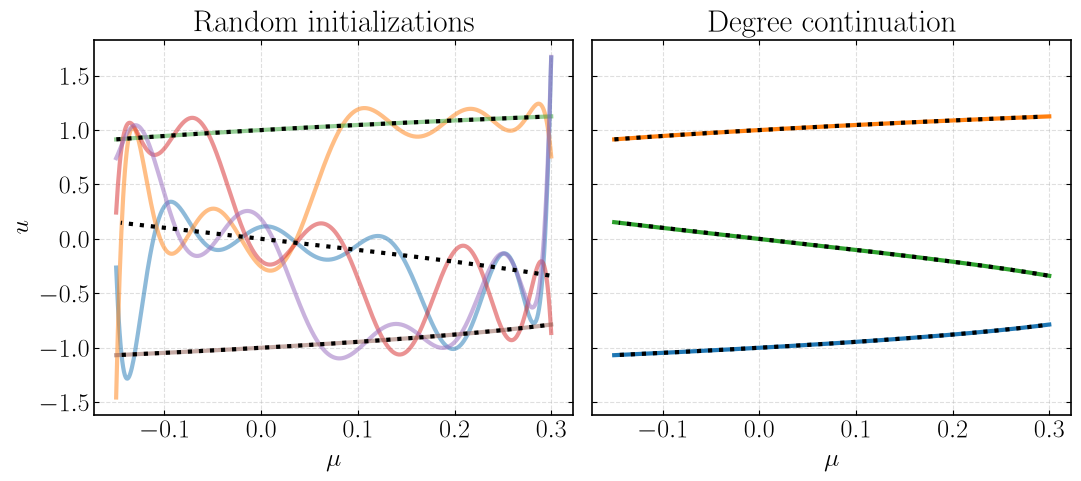

In [2]:
mu_bounds = (-0.15, 0.3)
N = 10
solver_osc = PCEGalerkin(rhs, jac, mu_bounds=mu_bounds, state_dim=1, quad_order=2 * N + 1)
all_roots = solver_osc.random_roots(N, n_samples=30, seed=2, scale=0.8)
branches = solver_osc.find_branches(N, n_samples=30, seed=2, unique_tol=1e-6, box=(-1.5, 1.5))

u_ex = np.linspace(-1.3, 1.3, 500)
mu_ex = u_ex**3 - u_ex
exact = [(mu_ex, np.where((mu_ex >= mu_bounds[0]) & (mu_ex <= mu_bounds[1]), u_ex, np.nan))]

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
plot_2d(solver_osc, all_roots, exact, branch_style="-", branch_lw=3.0, branch_zorder=2,
        branch_alpha=0.5, exact_style="k:", exact_lw=3.0, exact_zorder=5,
        title="Random initializations", ax=axes[0])
plot_2d(solver_osc, branches, exact, branch_style="-", branch_lw=3.0, branch_zorder=2,
        exact_style="k:", exact_lw=3.0, exact_zorder=5, ylabel=None,
        title="Degree continuation", ax=axes[1])
plt.tight_layout()
plt.show()

## 2. Uniqueness and convergence

On $I = [0.5, 1.5]$, after the fold in $\mu_+=\frac{2}{3\sqrt{3}}$, the system admits a unique analytical branch $\bar{u}(\mu)$ and satisfies the global uniqueness hypotheses, yielding exponential convergence to machine precision.

Estimated rho (linf): 5.9226


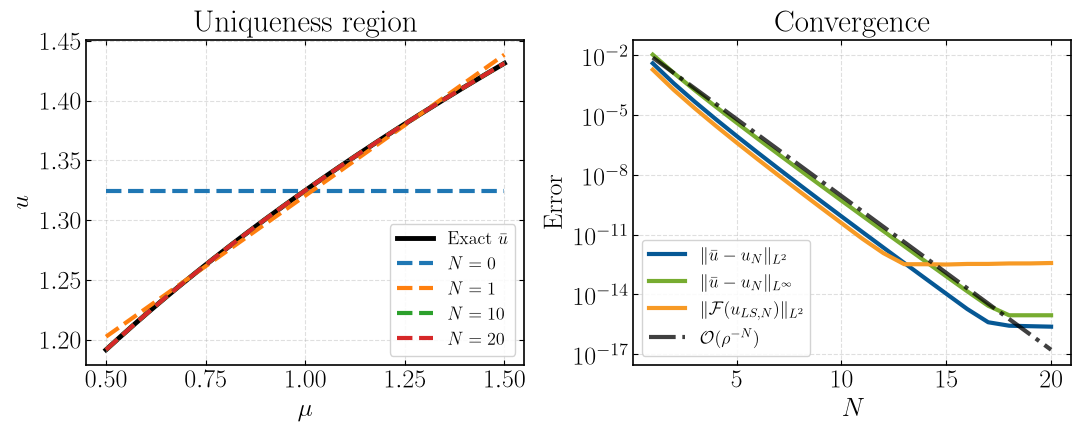

In [3]:
N_max = 20
plot_degrees = [0, 1, N_max // 2, N_max]
bounds_uq = (0.5, 1.5)
solver_uq = PCEGalerkin(rhs, jac, mu_bounds=bounds_uq, state_dim=1, quad_order=2 * N_max + 1)
history = solver_uq.continuation(N_max, u0=[1.2], return_history=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
mu_ex = np.linspace(bounds_uq[0], bounds_uq[1], 600)
plot_2d(solver_uq, [history[N] for N in plot_degrees], [(mu_ex, exact_unique(mu_ex))],
        branch_labels=[rf"$N={N}$" for N in plot_degrees], branch_lw=3.0,
        exact_lw=3.5, exact_label=r"Exact $\bar{u}$", title="Uniqueness region", ax=axes[0])
axes[0].legend(loc="lower right", framealpha=0.85)
plot_convergence(solver_uq, history, exact_unique,
                 ref_rates=[(r"$\mathcal{O}(\rho^{-N})$", "-.", None, "linf")], ax=axes[1])
plt.tight_layout()
plt.show()

## 3. Disconnected branches and fold

When an interval contains a saddle-node fold, degree continuation can extrapolate the partially supported branches only up to a finite degree before failing, leaving only the globally supported branch.

N=0: 3/3 branches converged
N=4: 3/3 branches converged
N=5: 1/3 branches converged


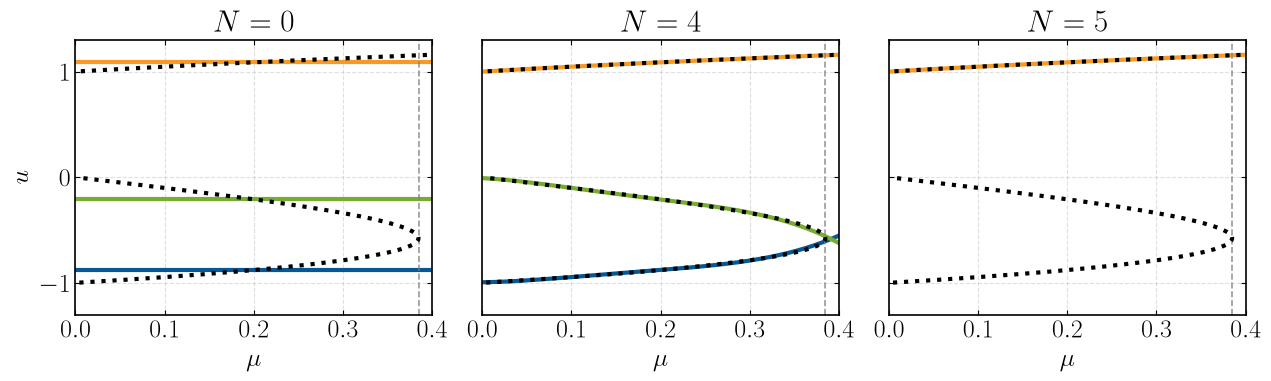

In [4]:
bounds_iso = (0.0, 0.4)
u0_list = [-1.0, -0.2, 1.0]
N_max_iso = 15
solver_iso = PCEGalerkin(rhs, jac, mu_bounds=bounds_iso, state_dim=1, quad_order=2 * N_max_iso + 1)
histories = [solver_iso.continuation(N_max_iso, u0=[u0], return_history=True, stop_on_fail=True)
             for u0 in u0_list]

n_last = min(max(h.keys()) for h in histories if h)
plot_N = sorted(set([0, n_last, n_last + 1])) if n_last < N_max_iso else [0, N_max_iso // 2, N_max_iso]

u_bg = np.linspace(-1.3, 1.3, 500)
mu_bg = u_bg**3 - u_bg
exact_iso = [(mu_bg, np.where((mu_bg >= bounds_iso[0]) & (mu_bg <= bounds_iso[1]), u_bg, np.nan))]
colors = ["#065895", "#77ac30", "#f79a25"]

fig, axes = plt.subplots(1, len(plot_N), figsize=(4.3 * len(plot_N), 4), sharey=True)
for idx_ax, (ax, N) in enumerate(zip(axes, plot_N)):
    active = [(idx, h[N]) for idx, h in enumerate(histories) if N in h]
    plot_2d(solver_iso, [c for _, c in active], exact_iso, branch_style="-",
            branch_lw=3.0, branch_zorder=2, colors=[colors[idx % len(colors)] for idx, _ in active],
            exact_style="k:", exact_lw=3.0, exact_zorder=5,
            ylabel=r"$u$" if idx_ax == 0 else None, title=rf"$N = {N}$",
            xlim=bounds_iso, ylim=(-1.3, 1.3), ax=ax)
    ax.axvline(mu_sn, color="gray", ls="--", lw=1.2, alpha=0.8)
    print(f"N={N}: {len(active)}/{len(u0_list)} branches converged")

plt.tight_layout()
plt.show()